Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# Clasificación de Imágenes de Perros y Gatos con VGG-16


En este Jupyter Notebook, vamos a desarrollar un clasificador de imágenes utilizando la arquitectura de red neuronal convolucional (CNN) conocida como VGG-16. Este modelo ha demostrado ser muy efectivo en tareas de clasificación de imágenes.

El objetivo es distinguir entre imágenes de perros y gatos. Para ello, utilizaremos un conjunto de datos que contiene 25,000 imágenes, con una distribución equitativa entre las dos clases. En este contexto, las etiquetas son 1 para los perros y 0 para los gatos.

VGG-16 es una arquitectura de CNN propuesta por K. Simonyan y A. Zisserman de la Universidad de Oxford en el paper "Very Deep Convolutional Networks for Large-Scale Image Recognition". Esta red es caracterizada por su simplicidad, utilizando solo capas convolucionales 3x3 apiladas una sobre otra en profundidad creciente.

Vamos a entrenar nuestro modelo en este conjunto de datos y evaluar su rendimiento. A lo largo de este notebook, exploraremos diferentes aspectos del proceso de entrenamiento y optimización del modelo, así como también la evaluación de su rendimiento.

1. Descargamos la base de datos de perros y gatos del sitio de Microsoft: [Kaggle Cats and Dogs Dataset](https://www.microsoft.com/en-us/download/details.aspx?id=54765)

2. El archivo original se llama "PetImages.zip" y contiene dos carpetas llamadas "Cat" y "Dog" con imágenes de gatos y perros respectivamente.

3. Para este ejercicio, reduciremos el número de imágenes a 161 de cada clase

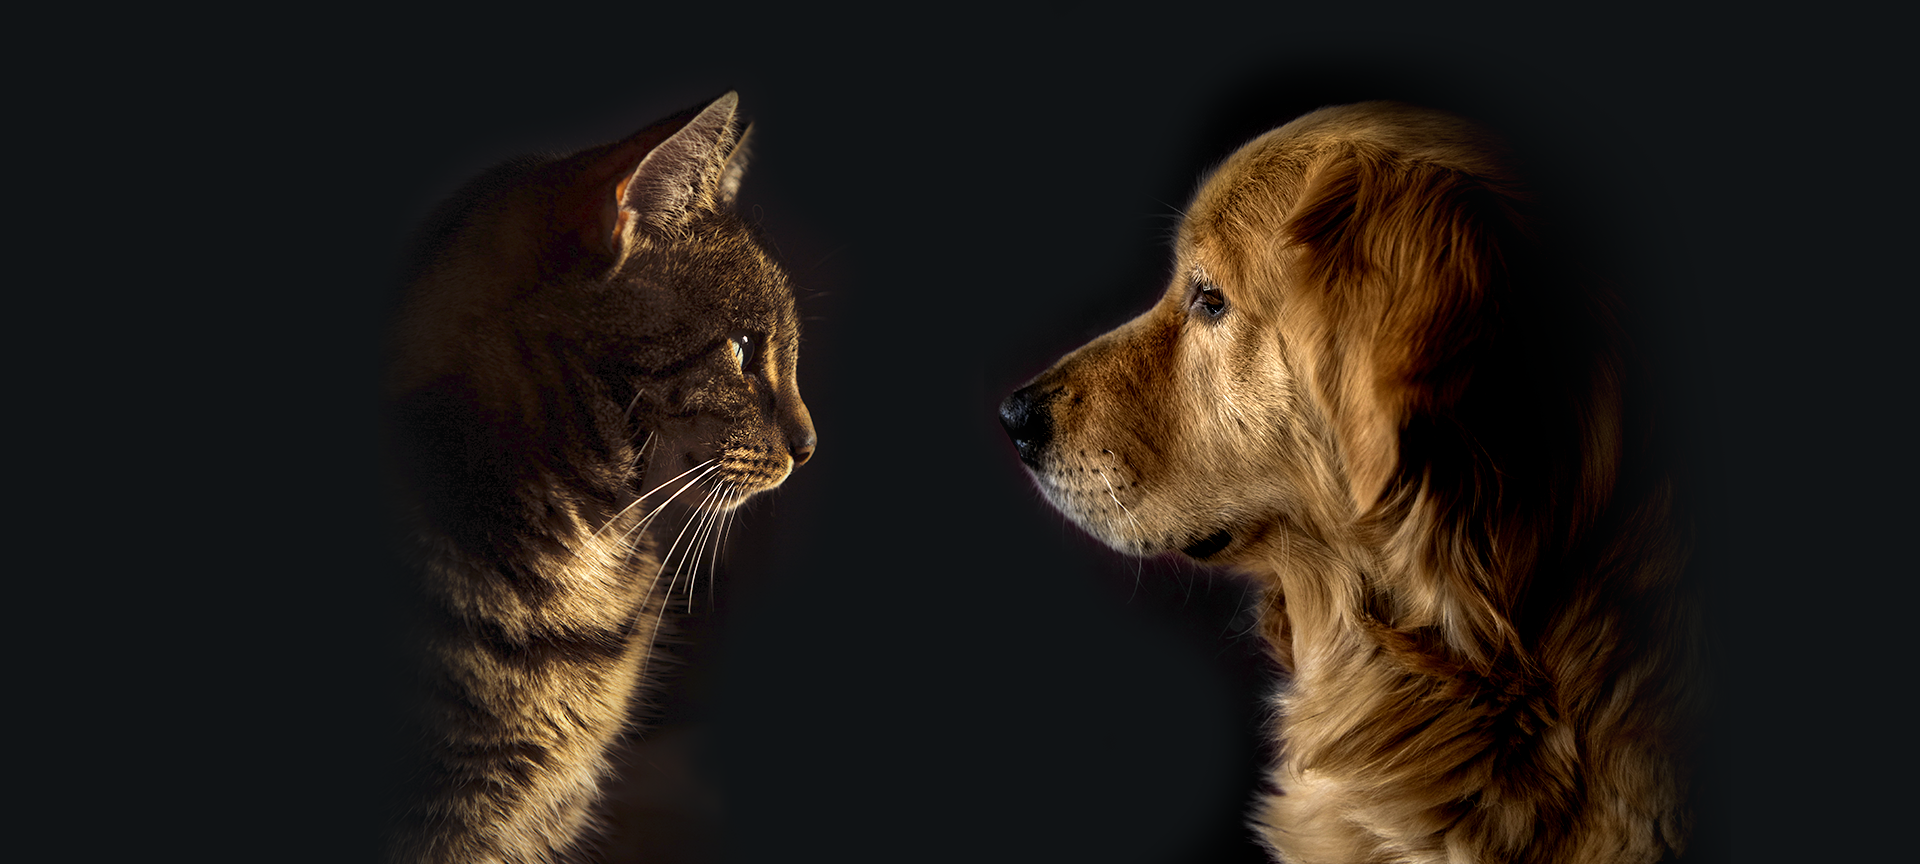

Primero, vamos a importar las bibliotecas necesarias:

In [ ]:
%pip install ipykernel
%pip install opencv-python
%pip install keras
%pip install scikit-learn
%pip install tensorflow
%pip install matplotlib

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from keras.applications import VGG16
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

2025-11-08 09:56:17.060574: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Cargamos las imágenes de perros y gatos:

In [2]:
def load_images(folder):
    # Inicializamos las listas para almacenar las imágenes y las etiquetas
    images = []
    labels = []

    # Obtener el nombre de la carpeta
    folder_name = os.path.basename(folder)

    # Iteramos sobre cada archivo en la carpeta especificada
    for filename in os.listdir(folder):
        # Leemos la imagen utilizando OpenCV
        img = cv2.imread(os.path.join(folder, filename))

        # Si la imagen se ha leído correctamente
        if img is not None:
            # Redimensionamos la imagen a 224x224 píxeles para que coincida con la dimensión de entrada de VGG-16
            img = cv2.resize(img, (224, 224))
            # Añadimos la imagen a la lista de imágenes
            images.append(img)

            # Asignamos la etiqueta correspondiente según la carpeta
            if folder_name == 'Dog_reduced':
                labels.append(1) # Etiqueta 1 para perros
            elif folder_name == 'Cat_reduced':
                labels.append(0) # Etiqueta 0 para gatos

    return images, labels

# Cargamos las imágenes y etiquetas de perros desde el directorio especificado
# La función load_images se encarga de leer las imágenes y sus etiquetas correspondientes
dogs_images, dogs_labels = load_images('/Users/eugenio/Documents/Notebooks_ArtificialIntelligence/5. Computer Vision/Data Bases/Dog_reduced')

# Cargamos las imágenes y etiquetas de gatos desde el directorio especificado
# Similar a la carga de imágenes de perros, esta función lee las imágenes de gatos y sus etiquetas
cats_images, cats_labels = load_images('/Users/eugenio/Documents/Notebooks_ArtificialIntelligence/5. Computer Vision/Data Bases/Cat_reduced')

# Combinamos los arrays de perros y gatos
images = np.array(dogs_images + cats_images)
labels = np.array(dogs_labels + cats_labels)
labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [3]:
from keras.utils import to_categorical

# One-hot encoding de las etiquetas
labels = to_categorical(labels) # Convertimos las etiquetas a formato one-hot encoding. Las etiquetas originales eran 0 y 1, y ahora se convierten en vectores binarios.
labels

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.

Dividmos los datos en conjuntos de entrenamiento y prueba:

In [4]:
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2)

Construimos y entrenamos la red neuronal convolucional VGG-16:

In [6]:
# Definimos el callback de EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10)

# Cargamos la red VGG16, asegurándonos de que se dejan fuera las capas superiores de la red preentrenada (head FC layer)
baseModel = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Construimos la capa que se colocará en la parte superior del modelo base (baseModel)
model = Sequential()
model.add(baseModel)
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))  # Agregamos una capa de Dropout con una tasa de 0.5
model.add(Dense(2, activation='softmax'))  # Dos clases (perro y gato), por lo que la capa de salida tiene 2 neuronas

# Congelamos las capas del modelo base para que no se actualicen durante el entrenamiento
for layer in baseModel.layers:
    layer.trainable = False

# Compilamos el modelo 
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Entrenamos el modelo
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=300, batch_size=32, callbacks=[early_stopping])

# Evaluamos el modelo
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Loss: {loss}')
print(f'Accuracy: {accuracy}')

Epoch 1/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 79s 10s/step - accuracy: 0.6667 - loss: 40.3309 - val_accuracy: 0.9062 - val_loss: 7.7283
Epoch 2/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 104s 13s/step - accuracy: 0.9333 - loss: 7.8597 - val_accuracy: 0.9844 - val_loss: 1.3810
Epoch 3/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 103s 14s/step - accuracy: 0.9725 - loss: 1.2238 - val_accuracy: 0.9844 - val_loss: 0.4662
Epoch 4/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 119s 16s/step - accuracy: 0.9961 - loss: 0.0676 - val_accuracy: 0.9688 - val_loss: 0.2000
Epoch 5/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 81s 10s/step - accuracy: 0.9961 - loss: 0.3557 - val_accuracy: 0.9688 - val_loss: 0.4584
Epoch 6/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 85s 11s/step - accuracy: 0.9922 - loss: 0.2968 - val_accuracy: 0.9844 - val_loss: 0.2085
Epoch 7/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 94s 12s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.9844 - val_loss: 0.4227
Epoch 8/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 85s 11s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.9844

**Opcional:** Guardamos el modelo en un archivo formato .h5 y lo cargamos en el dispositivo de despliegue

In [7]:
# Exportamos en modelo en un formato .h5
model.save('modelo_clasificacion_perros_gatos.h5')

In [ ]:
# Cargamos el modelo desde un archivo formato .h5
from keras.models import load_model
model = load_model('modelo_clasificacion_perros_gatos.h5')

Hacemos una predicción con una nueva imagen para comprobar que el modelo funciona

In [8]:
# Leemos una imagen nunca vista por el modelo utilizando OpenCV
img = cv2.imread('genaro.jpg')

# Redimensionamos la imagen a 224x224 píxeles para que coincida con la dimensión de entrada del modelo VGG-16
img = cv2.resize(img, (224, 224))

# Expandimos las dimensiones de la imagen para que tenga la forma (1, 224, 224, 3)
# Esto es necesario porque el modelo espera un lote de imágenes como entrada
img = np.expand_dims(img, axis=0)

# Realizamos la predicción utilizando el modelo cargado
pred = model.predict(img)

# Imprimimos la predicción
print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[1. 0.]]


Aunque `img` sea una sola imagen, el modelo siempre espera un lote (batch), y también devuelve un lote de predicciones.

`pred[0][0]` corresponde a la probabilidad de que la imagen sea un gato

`pred[0][1]` corresponde a la probabilidad de que la imagen sea un perro

La razón por la que siempre se utiliza `[0]` al inicio en `pred[0][0]` y `pred[0][1]` es porque el método predict de un modelo de Keras devuelve una matriz de predicciones, incluso si solo se pasa una imagen para la predicción.

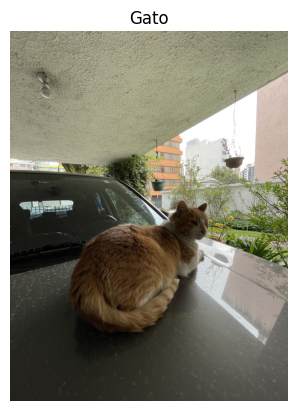

In [9]:
# Leemos una imagen nunca vista por el modelo utilizando OpenCV
img = cv2.imread('genaro.jpg')

# Convertimos la imagen de BGR (formato por defecto de OpenCV) a RGB (formato utilizado por Matplotlib)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

# Comprobamos cuál de las dos probabilidades es mayor en la predicción
if pred[0][0] > pred[0][1]:
    # Si la probabilidad de que sea un gato es mayor, imprimimos 'Gato'
    plt.title('Gato')
else:
    # Si la probabilidad de que sea un perro es mayor, imprimimos 'Perro'
    plt.title('Perro')

# Ocultamos los ejes de la imagen
plt.axis('off')  # Ocultamos los ejes
# Mostramos la imagen con la predicción
plt.show()

## Actividad calificable:

En esta actividad, llevaremos a cabo una serie de pruebas para evaluar la capacidad de nuestro modelo de clasificación de imágenes. El objetivo es identificar correctamente si una imagen contiene el rostro de un estudiante específico o si pertenece a un fondo. Para ello, hemos definido dos etiquetas principales:

##### **Label 1:** `Wilson Dugllay`  
##### **Label 2:** `Fondo` (imagenes que no contengan el rostro del estudiante)

#### **Pruebas:**

Las pruebas se realizarán con diferentes tipos de imágenes de entrada para verificar la precisión del modelo en escenarios no vistos durante el entrenamiento:

1. **Input image:** Foto del estudiante que no se encuentre en la carpeta de entrenamiento (tómate una foto el día de la presentación usando tu webcam).
**Required output label:** `Nombre del estudiante`

2. **Input image:** Fondo que no se encuentre en la carpeta de entrenamiento (el estudiante que presente antes de ti te dará la palabra de búsqueda, puedes descargarla de Google Images).  
**Required output label:** `Fondo`
3. **Input image:** Foto de un rostro diferente al rostro del estudiante que no se encuentre en las carpetas de entrenamiento (el estudiante que presente antes de ti te dará un nombre de una celebridad que se parezca a ti, puedes descargarla de Google Images).  
**Required output label:** `Fondo`

##### **Hyperparameter testing (Opcional):**

Además, puedes explorar el impacto de varios hiperparámetros en el rendimiento del modelo. Los hiperparámetros a ajustar incluyen:

-Aumento de imágenes en la base de datos  
-Cambio de función de pérdida (loss)  
-Cambio en el optimizador (optimizer)  
-Cambio en el número de épocas de entrenamiento (epochs)  
-Cambio en el número de tamaño de lote (batch_size)

Estas pruebas y ajustes te permitirán optimizar el modelo para obtener la mejor precisión posible en la clasificación de imágenes.

##### **Presentación de resultados**

Los estudiantes presentarán sus resultados en clase usando una app de `streamlit`. La calificación dependerá del éxito de las 3 pruebas.


## 1. Preparación del conjunto de datos

### Objetivo

Desarrollar un modelo de clasificación de imágenes mediante transferencia de aprendizaje con VGG-16, capaz de distinguir entre fotografías del estudiante y otras imágenes clasificadas como Fondo.

### Descripción de los datos

El conjunto de datos contiene 54 imágenes organizadas en dos categorías:

- **Mi_Rostro:** 24 fotografías del estudiante.
- **Fondo:** 30 imágenes de otras personas y diferentes escenarios.

Para preparar las imágenes se utiliza Python, Pillow y NumPy. Todas las fotografías se convierten a RGB y se redimensionan a 224 × 224 píxeles, tamaño requerido por VGG-16.

Se asignan etiquetas numéricas para la clasificación binaria:

- Fondo = 0.
- Mi_Rostro = 1.

Esta preparación permite utilizar las fotografías como datos de entrada para el modelo de aprendizaje profundo.


In [4]:

from pathlib import Path

# Ubicar las fotografías de nuestra actividad
base = Path("datos")

print("Directorio actual:", Path.cwd())

# Comprobar las dos categorías
for clase in ["Mi_Rostro", "Fondo"]:
    carpeta = base / clase

    if carpeta.exists():
        fotos = [
            archivo for archivo in carpeta.iterdir()
            if archivo.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        print(f"{clase}: {len(fotos)} imágenes")
    else:
        print(f"No se encontró: {carpeta}")


Directorio actual: c:\Users\eduar\Downloads\MD IA\Actividad 8
Mi_Rostro: 35 imágenes
Fondo: 35 imágenes


In [7]:

import numpy as np
from PIL import Image

X = []
y = []
nombres_archivos = []

clases = {
    "Fondo": 0,
    "Mi_Rostro": 1
}

for clase, etiqueta in clases.items():

    carpeta = base / clase

    for archivo in sorted(carpeta.iterdir()):

        if archivo.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(archivo) as imagen:
                imagen = imagen.convert("RGB")
                imagen = imagen.resize((224, 224))

                X.append(np.array(imagen))
                y.append(etiqueta)
                nombres_archivos.append(str(archivo))

        except Exception as error:
            print("Error al cargar:", archivo, error)

X = np.array(X, dtype=np.uint8)
y = np.array(y)

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Etiquetas:", clases)
print("Imágenes cargadas:", len(X))


Dimensiones de X: (70, 224, 224, 3)
Dimensiones de y: (70,)
Etiquetas: {'Fondo': 0, 'Mi_Rostro': 1}
Imágenes cargadas: 70


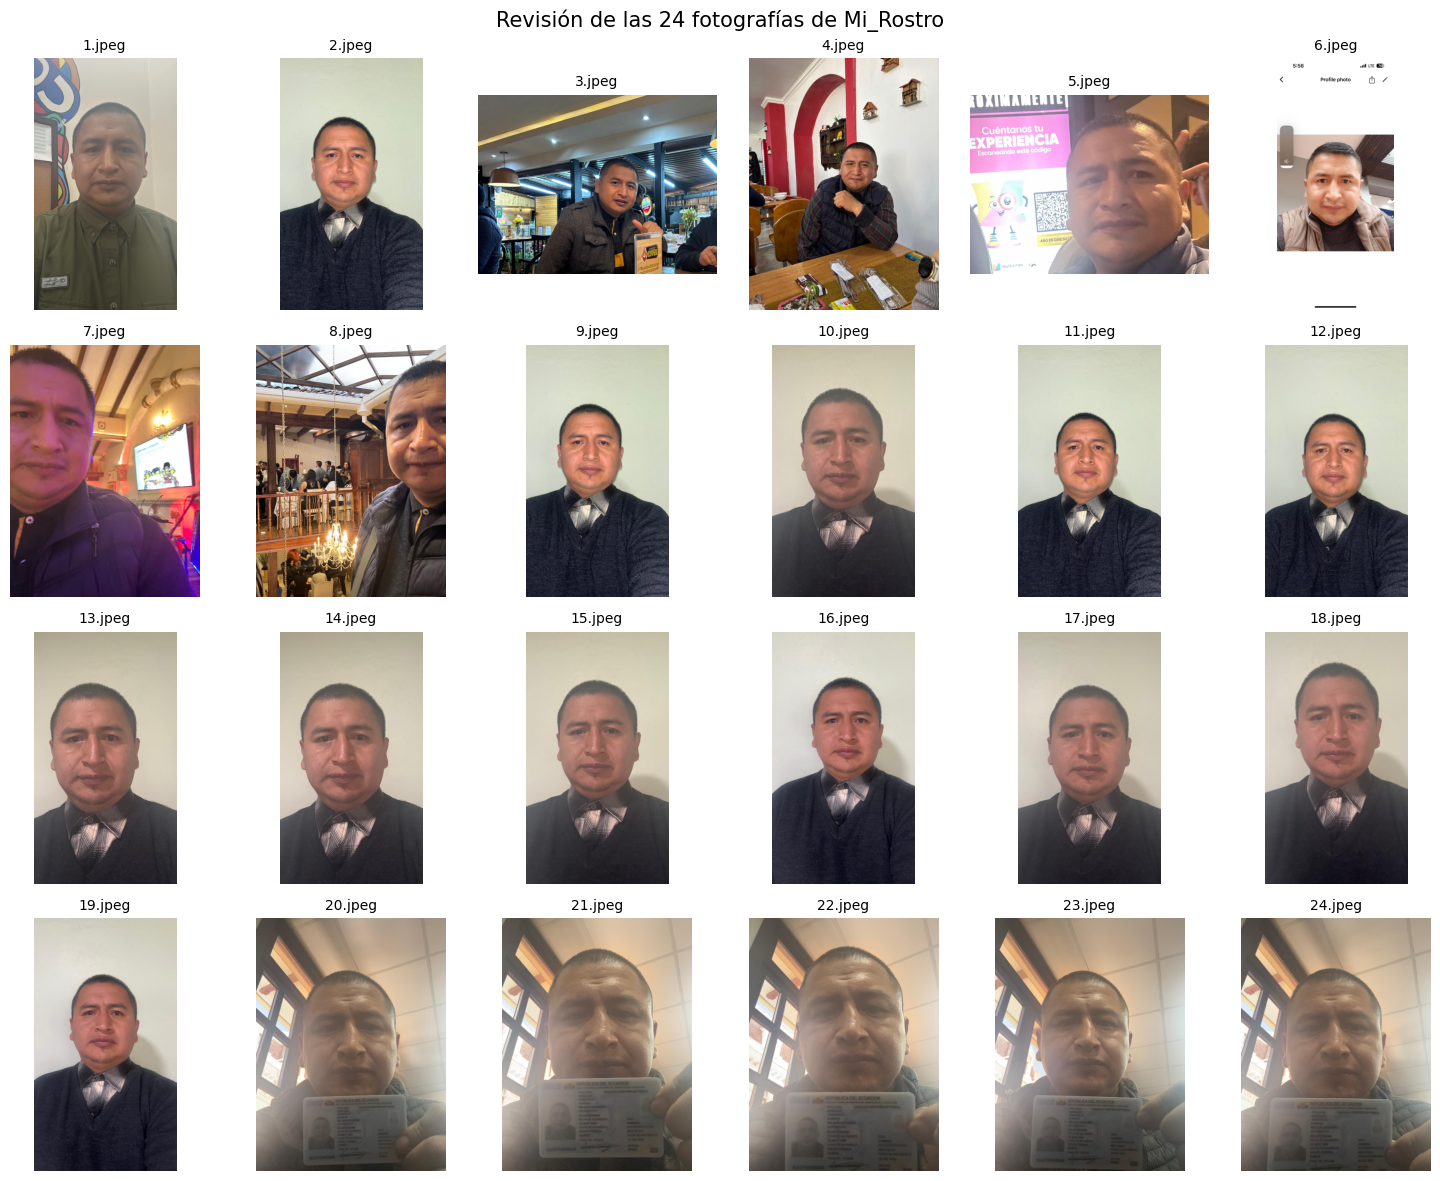

In [8]:

import matplotlib.pyplot as plt
from PIL import Image

# Obtener las fotografías de Mi_Rostro
carpeta_rostro = base / "Mi_Rostro"

fotos_rostro = sorted(
    [
        archivo for archivo in carpeta_rostro.iterdir()
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ],
    key=lambda archivo: int(archivo.stem)
    if archivo.stem.isdigit() else archivo.stem
)

# Mostrar las fotografías en una cuadrícula
fig, ejes = plt.subplots(4, 6, figsize=(15, 12))

for eje, archivo in zip(ejes.flat, fotos_rostro):
    with Image.open(archivo) as imagen:
        eje.imshow(imagen.convert("RGB"))

    eje.set_title(archivo.name, fontsize=10)
    eje.axis("off")

for eje in list(ejes.flat)[len(fotos_rostro):]:
    eje.axis("off")

plt.suptitle("Revisión de las 24 fotografías de Mi_Rostro", fontsize=15)
plt.tight_layout()
plt.show()


In [9]:

# Selección de fotografías variadas de Mi_Rostro

fotos_seleccionadas = {
    "1.jpeg", "2.jpeg", "3.jpeg", "4.jpeg",
    "5.jpeg", "6.jpeg", "7.jpeg", "8.jpeg",
    "9.jpeg", "14.jpeg", "19.jpeg", "22.jpeg"
}

# Obtener índices de las fotografías seleccionadas
indices_rostro = [
    i for i, nombre in enumerate(nombres_archivos)
    if Path(nombre).parent.name == "Mi_Rostro"
    and Path(nombre).name in fotos_seleccionadas
]

# Conservar las 30 imágenes de Fondo
indices_fondo = [
    i for i, nombre in enumerate(nombres_archivos)
    if Path(nombre).parent.name == "Fondo"
]

# Crear nuestro conjunto seleccionado
indices_seleccionados = indices_fondo + indices_rostro

X_seleccionado = X[indices_seleccionados]
y_seleccionado = y[indices_seleccionados]

print("Imágenes seleccionadas:", len(X_seleccionado))
print("Fondo:", np.sum(y_seleccionado == 0))
print("Mi_Rostro:", np.sum(y_seleccionado == 1))
print("Dimensiones:", X_seleccionado.shape)


Imágenes seleccionadas: 47
Fondo: 35
Mi_Rostro: 12
Dimensiones: (47, 224, 224, 3)


In [10]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import numpy as np

# Identificar las cinco fotografías nuevas
nombres_roberto = {
    f"Roberto{i}.jpg" for i in range(1, 6)
}

# Separar las 30 imágenes originales de Fondo
indices_fondo_original = [
    i for i, nombre in enumerate(nombres_archivos)
    if Path(nombre).parent.name == "Fondo"
    and Path(nombre).name not in nombres_roberto
]

# Identificar las cinco imágenes de Roberto
indices_roberto = [
    i for i, nombre in enumerate(nombres_archivos)
    if Path(nombre).name in nombres_roberto
    and Path(nombre).parent.name == "Fondo"
]

# Identificar las 12 fotografías seleccionadas de Mi_Rostro
indices_rostro = [
    i for i, nombre in enumerate(nombres_archivos)
    if Path(nombre).parent.name == "Mi_Rostro"
    and Path(nombre).name in fotos_seleccionadas
]

# Separación de Mi_Rostro
rostro_val = [
    i for i in indices_rostro
    if Path(nombres_archivos[i]).name in ["7.jpeg", "14.jpeg"]
]

rostro_test = [
    i for i in indices_rostro
    if Path(nombres_archivos[i]).name in ["1.jpeg", "22.jpeg"]
]

rostro_train = [
    i for i in indices_rostro
    if i not in rostro_val + rostro_test
]

# Separar las imágenes originales de Fondo
fondo_train, fondo_temp = train_test_split(
    indices_fondo_original,
    train_size=20,
    random_state=42
)

fondo_val, fondo_test = train_test_split(
    fondo_temp,
    test_size=5,
    random_state=42
)

# Incorporar Roberto exclusivamente al entrenamiento
idx_train = rostro_train + list(fondo_train) + indices_roberto
idx_val = rostro_val + list(fondo_val)
idx_test = rostro_test + list(fondo_test)

# Crear los conjuntos
X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

# Verificaciones
assert len(indices_fondo_original) == 30
assert len(indices_roberto) == 5
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nDistribución del entrenamiento:")
print("Fondo:", np.sum(y_train == 0))
print("Mi_Rostro:", np.sum(y_train == 1))
print("Fotografías de Roberto incorporadas:", len(indices_roberto))


Entrenamiento: (33, 224, 224, 3)
Validación: (7, 224, 224, 3)
Prueba: (7, 224, 224, 3)

Distribución del entrenamiento:
Fondo: 25
Mi_Rostro: 8
Fotografías de Roberto incorporadas: 5


In [11]:

import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

# Semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# Cargar VGG-16 desde ImageNet
base_nueva = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_nueva.trainable = False

# Construir el clasificador
entrada_nueva = layers.Input(shape=(224, 224, 3))

x = layers.RandomFlip("horizontal")(entrada_nueva)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.10)(x)

x = preprocess_input(x)
x = base_nueva(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.5)(x)

salida_nueva = layers.Dense(1, activation="sigmoid")(x)

modelo_nuevo = Model(entrada_nueva, salida_nueva)

modelo_nuevo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Equilibrar ambas categorías
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

pesos_clases = {
    0: float(pesos[0]),
    1: float(pesos[1])
}

# Evitar entrenamiento excesivo
detencion = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Entrenar con las 33 imágenes
historial_nuevo = modelo_nuevo.fit(
    X_train.astype("float32"),
    y_train,
    validation_data=(
        X_val.astype("float32"),
        y_val
    ),
    epochs=20,
    batch_size=4,
    class_weight=pesos_clases,
    callbacks=[detencion],
    verbose=1
)

print("\nEntrenamiento terminado.")


Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.6364 - loss: 2.4029 - val_accuracy: 0.8571 - val_loss: 0.7755
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5455 - loss: 1.7760 - val_accuracy: 0.8571 - val_loss: 0.8141
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5455 - loss: 1.4897 - val_accuracy: 0.8571 - val_loss: 0.8986
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.6667 - loss: 1.6051 - val_accuracy: 0.8571 - val_loss: 0.9901
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5152 - loss: 1.5791 - val_accuracy: 0.8571 - val_loss: 1.0613
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.6667 - loss: 0.8663 - val_accuracy: 0.8571 - val_loss: 1.0844

Entrenamiento terminado.


In [12]:

from pathlib import Path
from PIL import Image
import numpy as np

print("PRUEBAS DEL NUEVO MODELO VGG-16")
print("-" * 55)

for i in range(1, 6):
    ruta = Path(f"datos/Fondo/Roberto{i}.jpg")

    with Image.open(ruta) as imagen:
        imagen = imagen.convert("RGB")
        imagen = imagen.resize((224, 224))

    entrada = np.expand_dims(
        np.array(imagen, dtype=np.float32),
        axis=0
    )

    probabilidad = float(
        modelo_nuevo.predict(entrada, verbose=0)[0][0]
    )

    resultado = (
        "Mi_Rostro" if probabilidad >= 0.5 else "Fondo"
    )

    print(
        f"Roberto{i}.jpg | "
        f"Predicción: {resultado} | "
        f"Probabilidad Fondo: {(1 - probabilidad) * 100:.2f}%"
    )


PRUEBAS DEL NUEVO MODELO VGG-16
-------------------------------------------------------
Roberto1.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 8.29%
Roberto2.jpg | Predicción: Fondo | Probabilidad Fondo: 70.46%
Roberto3.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 1.08%
Roberto4.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 37.77%
Roberto5.jpg | Predicción: Fondo | Probabilidad Fondo: 92.15%


In [13]:

# Revisar las últimas capas de VGG-16
print("Últimas capas de VGG-16:")

for capa in base_nueva.layers[-6:]:
    print(capa.name, "| Entrenable:", capa.trainable)


Últimas capas de VGG-16:
block4_conv3 | Entrenable: False
block4_pool | Entrenable: False
block5_conv1 | Entrenable: False
block5_conv2 | Entrenable: False
block5_conv3 | Entrenable: False
block5_pool | Entrenable: False


In [14]:

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# Guardar una copia antes del ajuste fino
modelo_nuevo.save("modelo_antes_finetuning.keras")

# Habilitar el ajuste fino de la base VGG-16
base_nueva.trainable = True

# Mantener congeladas todas las capas excepto block5_conv3
for capa in base_nueva.layers:
    capa.trainable = (capa.name == "block5_conv3")

# Compilar nuevamente con aprendizaje muy lento
modelo_nuevo.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Detención temprana
detencion_fina = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Continuar entrenando el mismo modelo
historial_fino = modelo_nuevo.fit(
    X_train.astype("float32"),
    y_train,
    validation_data=(
        X_val.astype("float32"),
        y_val
    ),
    epochs=5,
    batch_size=4,
    class_weight=pesos_clases,
    callbacks=[detencion_fina],
    verbose=1
)

print("\nFine-tuning finalizado.")
print("Accuracy final de validación:",
      historial_fino.history["val_accuracy"][-1])


Epoch 1/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.6364 - loss: 1.6005 - val_accuracy: 0.8571 - val_loss: 0.7832
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.6970 - loss: 1.6297 - val_accuracy: 0.8571 - val_loss: 0.8002
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5455 - loss: 1.8557 - val_accuracy: 0.8571 - val_loss: 0.8167

Fine-tuning finalizado.
Accuracy final de validación: 0.8571428656578064



## 2. Construcción del modelo VGG-16 mediante transferencia de aprendizaje

Se utiliza la arquitectura VGG-16, preentrenada con ImageNet, para desarrollar un clasificador binario que distinga entre las categorías Fondo y Mi_Rostro.

Se conserva la base convolucional preentrenada y se congelan sus parámetros. Sobre esta base se incorporan nuevas capas de clasificación para adaptar el modelo a nuestra actividad.

También se aplican transformaciones aleatorias durante el entrenamiento para introducir variaciones en las imágenes y reducir el riesgo de sobreajuste.

La salida utiliza una función de activación sigmoide, que produce un valor entre 0 y 1 correspondiente a la predicción de la categoría Mi_Rostro.


In [15]:

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, Model

# Permitir reproducir el experimento
tf.keras.utils.set_random_seed(42)

# Cargar VGG-16 preentrenada
base_vgg16 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Congelar la base convolucional
base_vgg16.trainable = False

# Entrada del modelo
entrada = layers.Input(shape=(224, 224, 3))

# Aumento de datos durante el entrenamiento
x = layers.RandomFlip("horizontal")(entrada)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.10)(x)

# Preprocesamiento específico de VGG-16
x = preprocess_input(x)

# Extracción de características
x = base_vgg16(x, training=False)

# Capas de clasificación
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.5)(x)

# Salida binaria: Fondo = 0, Mi_Rostro = 1
salida = layers.Dense(1, activation="sigmoid")(x)

modelo = Model(inputs=entrada, outputs=salida)

# Compilación
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Modelo VGG-16 construido correctamente")
print("Capas de VGG-16 congeladas:", not base_vgg16.trainable)
print("Parámetros entrenables:",
      sum(tf.size(p).numpy() for p in modelo.trainable_weights))


Modelo VGG-16 construido correctamente
Capas de VGG-16 congeladas: True
Parámetros entrenables: 32897


In [16]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping

# Calcular pesos para equilibrar las clases
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

pesos_clases = {
    0: float(pesos[0]),
    1: float(pesos[1])
}

print("Pesos por clase:", pesos_clases)

# Detener el entrenamiento si deja de mejorar
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Entrenar el modelo VGG-16
historial = modelo.fit(
    X_train.astype("float32"),
    y_train,
    validation_data=(
        X_val.astype("float32"),
        y_val
    ),
    epochs=20,
    batch_size=4,
    class_weight=pesos_clases,
    callbacks=[early_stopping],
    verbose=1
)

print("\nEntrenamiento finalizado correctamente.")


Pesos por clase: {0: 0.66, 1: 2.0625}
Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6364 - loss: 2.4029 - val_accuracy: 0.8571 - val_loss: 0.7755
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5455 - loss: 1.7760 - val_accuracy: 0.8571 - val_loss: 0.8141
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5455 - loss: 1.4897 - val_accuracy: 0.8571 - val_loss: 0.8986
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6667 - loss: 1.6051 - val_accuracy: 0.8571 - val_loss: 0.9901
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5152 - loss: 1.5791 - val_accuracy: 0.8571 - val_loss: 1.0613
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6667 - loss: 0.8663 - val_accuracy: 0.8571 - val_loss: 1.0844

Entrenamiento finalizado correctamente.



## 3. Evaluación del modelo VGG-16

Se evalúa el modelo utilizando un conjunto de prueba independiente del entrenamiento, compuesto por cinco imágenes de Fondo y dos fotografías del estudiante.

Se calculan las métricas Accuracy, Precision, Recall y F1-score, además de la matriz de confusión.

Debido al tamaño reducido del conjunto de prueba, los resultados se consideran exploratorios y deberán complementarse con fotografías nuevas.


In [17]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
import numpy as np

# Evaluar el modelo con las imágenes de prueba
loss_test, accuracy_test = modelo.evaluate(
    X_test.astype("float32"),
    y_test,
    verbose=0
)

# Obtener probabilidades y clasificaciones
probabilidades = modelo.predict(
    X_test.astype("float32"),
    verbose=0
).ravel()

predicciones = (probabilidades >= 0.5).astype(int)

print("RESULTADOS DEL MODELO VGG-16")
print(f"Accuracy: {accuracy_test * 100:.2f}%")
print(f"Loss: {loss_test:.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(
    y_test,
    predicciones,
    labels=[0, 1]
))

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    predicciones,
    labels=[0, 1],
    target_names=["Fondo", "Mi_Rostro"],
    zero_division=0
))


RESULTADOS DEL MODELO VGG-16
Accuracy: 71.43%
Loss: 1.0453

Matriz de confusión:
[[4 1]
 [1 1]]

Reporte de clasificación:
              precision    recall  f1-score   support

       Fondo       0.80      0.80      0.80         5
   Mi_Rostro       0.50      0.50      0.50         2

    accuracy                           0.71         7
   macro avg       0.65      0.65      0.65         7
weighted avg       0.71      0.71      0.71         7



In [2]:

import tensorflow as tf
from pathlib import Path

# Cargar el modelo VGG-16 que entrenamos anteriormente
ruta_modelo = Path("modelo_rostro_vgg16_final.keras")

modelo = tf.keras.models.load_model(
    ruta_modelo,
    compile=False
)

print("Modelo VGG-16 cargado correctamente.")


Modelo VGG-16 cargado correctamente.


Predicción: Mi_Rostro
Probabilidad Mi_Rostro: 68.56%
Probabilidad Fondo: 31.44%


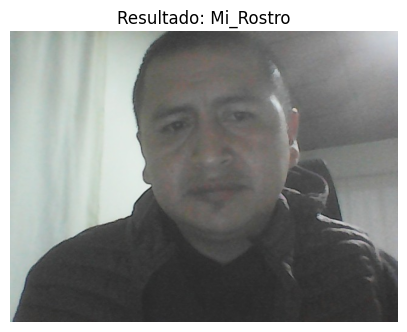

In [4]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cargar una fotografía nueva
ruta_foto = Path("foto_nueva15.jpg")

with Image.open(ruta_foto) as img:
    foto_original = img.convert("RGB")
    foto_modelo = foto_original.resize((224, 224))

# Preparar imagen para VGG-16
entrada_foto = np.expand_dims(
    np.array(foto_modelo, dtype=np.float32),
    axis=0
)

# El modelo ya incluye preprocess_input
probabilidad = float(
    modelo.predict(entrada_foto, verbose=0)[0][0]
)

resultado = "Mi_Rostro" if probabilidad >= 0.5 else "Fondo"

print("Predicción:", resultado)
print(f"Probabilidad Mi_Rostro: {probabilidad * 100:.2f}%")
print(f"Probabilidad Fondo: {(1 - probabilidad) * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(foto_original)
plt.title(f"Resultado: {resultado}")
plt.axis("off")
plt.show()

Predicción: Fondo
Probabilidad de Mi_Rostro: 0.01%
Probabilidad de Fondo: 99.99%


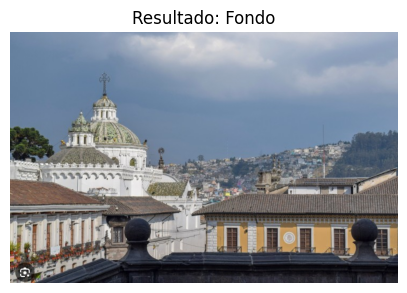

In [18]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

ruta = Path("foto_fondo1.jpg")

with Image.open(ruta) as img:
    imagen_original = img.convert("RGB")
    imagen_modelo = imagen_original.resize((224, 224))

entrada = np.expand_dims(
    np.array(imagen_modelo, dtype=np.float32),
    axis=0
)

probabilidad = float(
    modelo.predict(entrada, verbose=0)[0][0]
)

resultado = "Mi_Rostro" if probabilidad >= 0.5 else "Fondo"

print("Predicción:", resultado)
print(f"Probabilidad de Mi_Rostro: {probabilidad * 100:.2f}%")
print(f"Probabilidad de Fondo: {(1 - probabilidad) * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(imagen_original)
plt.title(f"Resultado: {resultado}")
plt.axis("off")
plt.show()


RESULTADO DE LA TERCERA PRUEBA
Predicción: Fondo
Probabilidad Mi_Rostro: 29.54%
Probabilidad Fondo: 70.46%


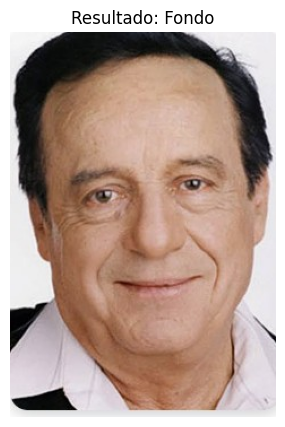

In [20]:
# Tercera prueba: rostro de otra persona

ruta_persona = Path("foto_otra_persona4.jpg")

with Image.open(ruta_persona) as img:
    persona_original = img.convert("RGB")
    persona_modelo = persona_original.resize((224, 224))

entrada_persona = np.expand_dims(
    np.array(persona_modelo, dtype=np.float32),
    axis=0
)

# Realizar predicción
prob_persona = float(
    modelo.predict(entrada_persona, verbose=0)[0][0]
)

resultado_persona = (
    "Mi_Rostro" if prob_persona >= 0.5 else "Fondo"
)

print("RESULTADO DE LA TERCERA PRUEBA")
print("Predicción:", resultado_persona)
print(f"Probabilidad Mi_Rostro: {prob_persona * 100:.2f}%")
print(f"Probabilidad Fondo: {(1 - prob_persona) * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(persona_original)
plt.title(f"Resultado: {resultado_persona}")
plt.axis("off")
plt.show()


## 4. Implementación del modelo en Streamlit

El modelo VGG-16 se guarda en formato Keras para permitir su utilización en una aplicación interactiva desarrollada con Streamlit.

La aplicación permitirá cargar fotografías y utilizar una cámara web para clasificar imágenes en las categorías Mi_Rostro y Fondo.

En las tres pruebas exploratorias realizadas con imágenes externas, el modelo produjo las clasificaciones esperadas. Sin embargo, estos resultados no garantizan su desempeño con cualquier fotografía nueva.


In [14]:

from pathlib import Path

# Guardar el modelo VGG-16 entrenado
ruta_modelo = Path("modelo_rostro_vgg16_final.keras")

modelo.save(ruta_modelo)

print("Modelo guardado correctamente.")
print("Archivo:", ruta_modelo.resolve())
print(
    "Tamaño:",
    round(ruta_modelo.stat().st_size / (1024 ** 2), 2),
    "MB"
)


Modelo guardado correctamente.
Archivo: C:\Users\eduar\Downloads\MD IA\Actividad 8\modelo_rostro_vgg16_final.keras
Tamaño: 56.61 MB



## 5. Resultados, conclusiones y recomendaciones

### 5.1. Resultados obtenidos

Se desarrolló un clasificador binario de imágenes utilizando transferencia de aprendizaje con la arquitectura VGG-16, preentrenada con ImageNet.

El conjunto original estuvo compuesto por 54 imágenes, distribuidas en 24 fotografías del estudiante y 30 imágenes de Fondo. Después de revisar la similitud entre fotografías, se seleccionaron 42 imágenes para el experimento.

Los datos se organizaron de la siguiente manera:

| Conjunto | Fondo | Mi_Rostro | Total |
|---|---:|---:|---:|
| Entrenamiento | 20 | 8 | 28 |
| Validación | 5 | 2 | 7 |
| Prueba | 5 | 2 | 7 |
| **Total** | **30** | **12** | **42** |

El modelo obtuvo los siguientes resultados:

- **Accuracy de validación:** 85,71%.
- **Accuracy de prueba:** 71,43%.
- **Precision de Mi_Rostro:** 50%.
- **Recall de Mi_Rostro:** 50%.
- **F1-score de Mi_Rostro:** 0,50.

La matriz de confusión del conjunto de prueba fue:

| Clase real | Predicción Fondo | Predicción Mi_Rostro |
|---|---:|---:|
| Fondo | 4 | 1 |
| Mi_Rostro | 1 | 1 |

### 5.2. Pruebas realizadas en Streamlit

Se implementó una aplicación interactiva con Streamlit, que permite cargar fotografías y tomar imágenes mediante una webcam.

Las pruebas exploratorias produjeron los siguientes resultados:

| Prueba | Clasificación obtenida | Probabilidad de la clase predicha |
|---|---|---:|
| Fotografía nueva del estudiante | Mi_Rostro | 78,34% |
| Fotografía de una llama | Fondo | 99,99% |
| Fotografía de otra persona | Fondo | 66,73% |
| Fotografía del estudiante mediante webcam, con iluminación mejorada | Mi_Rostro | 67,70% |

Se realizó también una prueba inicial con webcam que clasificó incorrectamente al estudiante como Fondo, con una probabilidad del 59,90%. Una segunda fotografía, con condiciones de iluminación diferentes, permitió obtener la clasificación esperada.

### 5.3. Conclusiones

1. La transferencia de aprendizaje permitió adaptar una arquitectura VGG-16 preentrenada para clasificar imágenes del estudiante y otras imágenes agrupadas en la categoría Fondo.

2. El modelo alcanzó un Accuracy del 71,43% en el conjunto de prueba. Este resultado evidencia un desempeño inicial, aunque la cantidad de imágenes evaluadas es reducida.

3. Las pruebas realizadas con archivos externos en Streamlit obtuvieron las clasificaciones esperadas. También se consiguió una clasificación correcta mediante webcam bajo condiciones de iluminación favorables.

4. El desempeño del modelo presentó sensibilidad a las condiciones de captura, especialmente a los cambios de iluminación. Por tanto, el éxito en determinadas imágenes no garantiza un reconocimiento correcto en todas las situaciones.

5. Streamlit permitió integrar el modelo entrenado en una interfaz interactiva, facilitando su utilización y demostración.

### 5.4. Recomendaciones

1. Ampliar el conjunto de entrenamiento con fotografías del estudiante tomadas bajo diferentes condiciones de iluminación, ángulos, vestimenta y fondos.

2. Incorporar más imágenes de personas diferentes para fortalecer la capacidad del clasificador de distinguir entre el estudiante y otros rostros.

3. Evaluar el modelo con un conjunto de prueba más amplio y representativo, utilizando imágenes que no hayan participado en el entrenamiento.

4. Mantener condiciones adecuadas de iluminación durante las demostraciones con webcam.

5. Considerar futuros experimentos de ajuste fino de VGG-16 para estudiar posibles mejoras en la clasificación, procurando controlar el sobreajuste.



## 6. Evidencias de las pruebas realizadas en Streamlit

### Objetivo

Documentar las pruebas realizadas con el modelo VGG-16 mediante la aplicación Streamlit, utilizando fotografías externas que no participaron en el entrenamiento.

Se realizaron cuatro pruebas:

1. Fotografía nueva del estudiante.
2. Imagen desconocida de Fondo.
3. Fotografía de otra persona.
4. Fotografía nueva del estudiante capturada mediante webcam.

Las cuatro fotografías seleccionadas obtuvieron la clasificación esperada. En una prueba previa con webcam se produjo una clasificación incorrecta, lo que evidencia la sensibilidad del modelo a las condiciones de iluminación.

A continuación, se presentan las fotografías utilizadas y las probabilidades estimadas por el modelo.


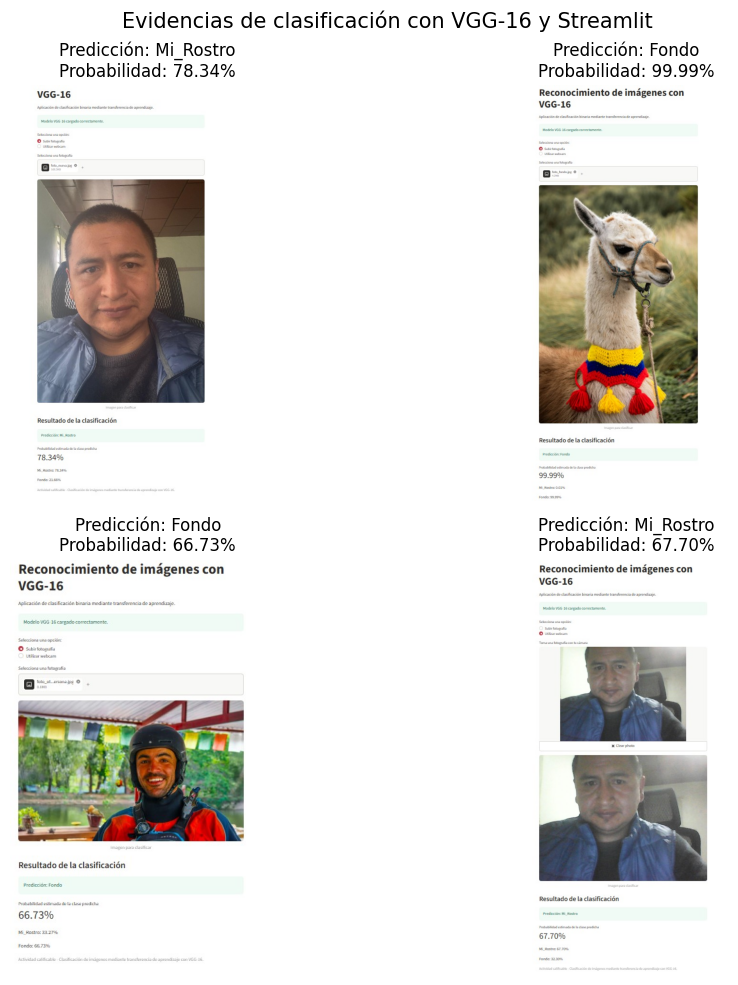

In [16]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Evidencias de las pruebas externas
pruebas = [
    (
        "Prueba_mi_rostro.jpg",
        "Mi_Rostro",
        78.34
    ),
    (
        "Prueba_foto_fondo.jpg",
        "Fondo",
        99.99
    ),
    (
        "Prueba_foto_otra_persona.jpg",
        "Fondo",
        66.73
    ),
    (
        "Prueba_foto_nueva_tomada_webcam.jpg",
        "Mi_Rostro",
        67.70
    )
]

fig, ejes = plt.subplots(2, 2, figsize=(12, 10))

for eje, (archivo, resultado, probabilidad) in zip(
    ejes.flat, pruebas
):
    ruta = Path(archivo)

    if not ruta.exists():
        eje.text(
            0.5, 0.5,
            f"No se encontró:\n{archivo}",
            ha="center", va="center"
        )
        eje.axis("off")
        continue

    with Image.open(ruta) as imagen:
        eje.imshow(imagen.convert("RGB"))

    eje.set_title(
        f"Predicción: {resultado}\n"
        f"Probabilidad: {probabilidad:.2f}%",
        fontsize=12
    )

    eje.axis("off")

plt.suptitle(
    "Evidencias de clasificación con VGG-16 y Streamlit",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [26]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Cargar el modelo que ya entrenamos
modelo_actualizado = tf.keras.models.load_model(
    "modelo_rostro_vgg16_final.keras",
    compile=False
)

# 2. Recuperar las mismas imágenes del entrenamiento original
carpeta_fondo = Path("datos/Fondo")
carpeta_rostro = Path("datos/Mi_Rostro")

# Excluir las cinco fotografías nuevas de la selección original
fotos_fondo_original = sorted([
    p for p in carpeta_fondo.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and p.name not in {f"Roberto{i}.jpg" for i in range(1, 6)}
])

assert len(fotos_fondo_original) == 30

# Recuperar las 20 imágenes originales de entrenamiento
fondo_train, _ = train_test_split(
    fotos_fondo_original,
    train_size=20,
    random_state=42
)

# Ocho fotografías utilizadas originalmente para entrenar
fotos_rostro = [
    carpeta_rostro / f"{i}.jpeg"
    for i in [2, 3, 4, 5, 6, 8, 9, 19]
]

# Cinco fotografías nuevas de Roberto
fotos_roberto = [
    carpeta_fondo / f"Roberto{i}.jpg"
    for i in range(1, 6)
]

# 3. Preparar las imágenes
X_actualizacion = []
y_actualizacion = []

for archivo, etiqueta in (
    [(p, 0) for p in fondo_train]
    + [(p, 1) for p in fotos_rostro]
    + [(p, 0) for p in fotos_roberto]
):
    with Image.open(archivo) as img:
        img = img.convert("RGB").resize((224, 224))
        X_actualizacion.append(np.array(img, dtype=np.float32))
        y_actualizacion.append(etiqueta)

X_actualizacion = np.array(X_actualizacion)
y_actualizacion = np.array(y_actualizacion)

print("Imágenes de entrenamiento:", len(X_actualizacion))
print("Fondo:", sum(y_actualizacion == 0))
print("Mi_Rostro:", sum(y_actualizacion == 1))

# 4. Compilar el modelo con una tasa de aprendizaje baja
modelo_actualizado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Equilibrar las clases
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_actualizacion
)

pesos_clases = {
    0: float(pesos[0]),
    1: float(pesos[1])
}

# 5. Continuar el entrenamiento
modelo_actualizado.fit(
    X_actualizacion,
    y_actualizacion,
    epochs=8,
    batch_size=4,
    class_weight=pesos_clases,
    verbose=1
)

# 6. Guardar sin sobrescribir el modelo original
modelo_actualizado.save(
    "modelo_rostro_vgg16_actualizado.keras"
)

print("\nModelo actualizado y guardado correctamente.")


Imágenes de entrenamiento: 33
Fondo: 25
Mi_Rostro: 8
Epoch 1/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 718ms/step - accuracy: 0.6667 - loss: 1.5422
Epoch 2/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 675ms/step - accuracy: 0.6061 - loss: 2.0334
Epoch 3/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 774ms/step - accuracy: 0.5152 - loss: 1.5647
Epoch 4/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 772ms/step - accuracy: 0.4848 - loss: 2.1819
Epoch 5/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 726ms/step - accuracy: 0.5758 - loss: 2.2623
Epoch 6/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6364 - loss: 1.0840
Epoch 7/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 983ms/step - accuracy: 0.6667 - loss: 1.8954
Epoch 8/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 805ms/step - accuracy: 0.6061 - loss: 2.0047

Modelo actualizado y guardado correctamente.


In [28]:

import tensorflow as tf

modelo = tf.keras.models.load_model(
    "modelo_rostro_vgg16_actualizado.keras",
    compile=False
)

print("Modelo actualizado cargado correctamente")


Modelo actualizado cargado correctamente


In [30]:

from pathlib import Path
from PIL import Image
import numpy as np

print("PRUEBAS CON LAS 5 FOTOGRAFÍAS DE ROBERTO")
print("-" * 55)

for i in range(1, 6):
    ruta = Path(f"datos/Fondo/Roberto{i}.jpg")

    with Image.open(ruta) as imagen:
        imagen = imagen.convert("RGB")
        imagen = imagen.resize((224, 224))

    entrada = np.expand_dims(
        np.array(imagen, dtype=np.float32),
        axis=0
    )

    prob = float(
        modelo.predict(entrada, verbose=0)[0][0]
    )

    resultado = "Mi_Rostro" if prob >= 0.5 else "Fondo"

    print(
        f"Roberto{i}.jpg | "
        f"Predicción: {resultado} | "
        f"Probabilidad Fondo: {(1 - prob) * 100:.2f}%"
    )


PRUEBAS CON LAS 5 FOTOGRAFÍAS DE ROBERTO
-------------------------------------------------------
Roberto1.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 8.19%
Roberto2.jpg | Predicción: Fondo | Probabilidad Fondo: 72.83%
Roberto3.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 1.18%
Roberto4.jpg | Predicción: Mi_Rostro | Probabilidad Fondo: 39.56%
Roberto5.jpg | Predicción: Fondo | Probabilidad Fondo: 90.79%
